# Data Visualization — Term 481 — Assignment 2

**Instructions:**
- Work through each exercise in order. Each exercise has a **"Your Code"** cell for you to complete, followed by a cell showing the **expected output**.
- Where an exercise asks a question, write your answer in the **"Your Answer"** markdown cell that follows it.
- Use `matplotlib` and `seaborn` unless an exercise says otherwise. Some exercises also use `scipy`, `scikit-learn`, `statsmodels` and `networkx`. If one is missing, install it with `!pip install <package>`.
- Built-in Seaborn datasets used in this assignment: `penguins` and `flights`. They are loaded with `sns.load_dataset(...)` (requires internet access the first time).
- All other data is given inside the exercise cells, so no CSV files are needed.
- Your plots do not have to match the expected output pixel for pixel, but they must show the same information, titles and labels.
- **Total: 50 points.** Run the setup cell below first.

In [63]:
#Ahmed Sultan Alsuhaymi__ 
 #471110797 

In [9]:
# Setup — run this first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
%matplotlib inline

print("Libraries loaded. Seaborn version:", sns.__version__)

Libraries loaded. Seaborn version: 0.13.2


---
## Part A — Descriptive Statistics and Comparing Distributions

The final-exam scores of 30 students are given below:

```python
scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
```

### Exercise A1 — Measures of Centrality and Dispersion (2 points)
Using NumPy (and `statistics.multimode` for the mode), compute and print:
1. The **mean**, **median** and **mode(s)** of the scores.
2. The **range**, **sample variance** and **sample standard deviation** (use `ddof=1`).
3. **Q1**, **Q3** and the **interquartile range (IQR)**.
4. Using the **1.5 × IQR rule**, the lower and upper fences and any scores that are **outliers**.

Round all values to 2 decimal places.

In [10]:
from statistics import multimode

scores = [62, 71, 75, 68, 80, 85, 91, 77, 73, 69, 88, 95, 59, 74, 81,
          77, 66, 72, 84, 77, 90, 63, 70, 79, 86, 98, 45, 76, 82, 71]
scores = np.array(scores)
mean_val = np.mean(scores)
median_val = np.median(scores)
modes_val = multimode(scores.tolist())

# 2. Dispersion
range_val = np.ptp(scores)  # أو np.max(scores) - np.min(scores)
var_val = np.var(scores, ddof=1)
std_val = np.std(scores, ddof=1)

# 3. Quartiles & IQR
q1, q3 = np.percentile(scores, [25, 75])
iqr_val = q3 - q1

# 4. Outliers (1.5 * IQR rule)
lower_fence = q1 - 1.5 * iqr_val
upper_fence = q3 + 1.5 * iqr_val
outliers = scores[(scores < lower_fence) | (scores > upper_fence)].tolist()

print(f"Mean   : {mean_val:.2f}")
print(f"Median : {median_val:.2f}")
print(f"Mode(s): {modes_val}")
print(f"Range             : {range_val}")
print(f"Sample variance   : {var_val:.2f}")
print(f"Sample std. dev.  : {std_val:.2f}")
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr_val:.2f}")
print(f"Lower fence = {lower_fence:.2f}, Upper fence = {upper_fence:.2f}")
print(f"Outliers: {outliers}")


Mean   : 76.13
Median : 76.50
Mode(s): [77]
Range             : 53
Sample variance   : 127.15
Sample std. dev.  : 11.28
Q1 = 70.25, Q3 = 83.50, IQR = 13.25
Lower fence = 50.38, Upper fence = 103.38
Outliers: [45]


In [11]:
# The output generated by the code written to answer this question should be as follows:

### Exercise A2 — Histogram and Box Plot Side by Side (2 points)
Create **one figure with two subplots** (1 row × 2 columns, `figsize=(14, 5)`):
- **Left:** a histogram of `scores` with **10 bins**. Draw a **red dashed** vertical line at the mean and a **green solid** vertical line at the median (`ax.axvline`). Add a legend showing both values.
- **Right:** a box plot of `scores` (Matplotlib `ax.boxplot` or `sns.boxplot`).

Give each subplot a title and axis labels, add an overall title with `fig.suptitle`, and use `plt.tight_layout()`.

Looking at the two plots, is the distribution **left-skewed**, **right-skewed** or roughly **symmetric**? How does the outlier from A1 appear in the box plot?

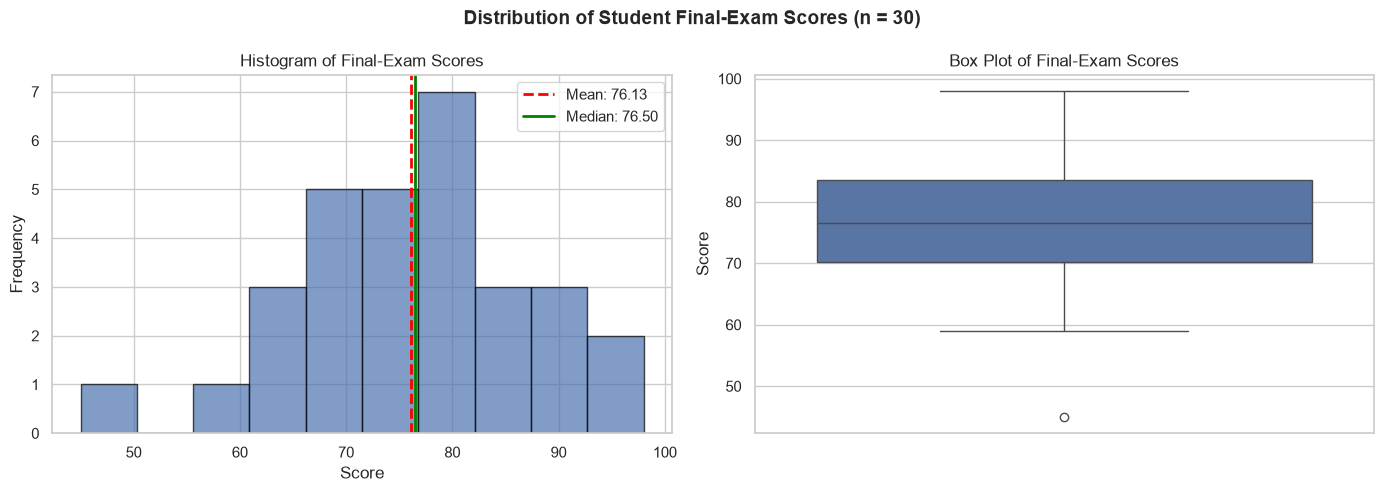

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram
axes[0].hist(scores, bins=10, edgecolor='black', alpha=0.7)
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')
axes[0].set_title("Histogram of Final-Exam Scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Right: Box Plot
sns.boxplot(y=scores, ax=axes[1])
axes[1].set_title("Box Plot of Final-Exam Scores")
axes[1].set_ylabel("Score")

fig.suptitle("Distribution of Student Final-Exam Scores (n = 30)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# The output generated by the code written to answer this question should be as follows:
# The distribution is slightly left-skewed (negatively skewed) because there is a tail extending toward the lower values (specifically the score of 45), which pulls the mean (76.13) slightly below the median (76.50).
# In the box plot, the outlier (45) appears as an individual dot/diamond plotted below the bottom whisker (the lower fence).

**Your Answer:**

_Double-click this cell and write your answer here._
The distribution is slightly left-skewed (negatively skewed) because there is a tail extending toward the lower values (specifically the score of 45), which pulls the mean (76.13) slightly below the median (76.50).
# In the box plot, the outlier (45) appears as an individual dot/diamond plotted below the bottom whisker (the lower fence).

### Exercise A3 — Comparing Two Distributions (2 points)
Two sections took the same quiz:

```python
section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]
```
1. Use the **Shapiro-Wilk test** to check whether each section follows a normal distribution (α = 0.05).
2. Use **Student's t-test** (`ttest_ind`) and the **Mann-Whitney U test** (`mannwhitneyu`) to check whether the two sections have equal means. Print each p-value and the decision (reject / fail to reject H₀).
3. Draw **side-by-side box plots** of the two sections with a title and labelled ticks.

Based on the tests **and** the box plots, are the two sections similar? Explain why the box plot tells you something the t-test does not.

Shapiro-Wilk Section 1: p-value = 0.9911 -> Fail to reject H0
Shapiro-Wilk Section 2: p-value = 0.0101 -> Reject H0

Student's t-test   : p-value = 0.7468 -> Fail to reject H0
Mann-Whitney U test : p-value = 0.6274 -> Fail to reject H0


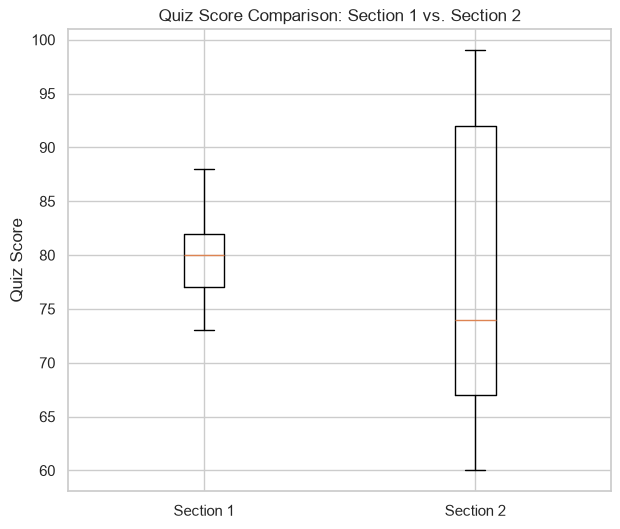

In [15]:
from scipy.stats import shapiro, ttest_ind, mannwhitneyu

section_1 = [78, 82, 75, 80, 85, 79, 77, 83, 81, 76, 74, 88, 79,
             82, 80, 84, 73, 78, 86, 81, 77, 79, 83, 80, 76]
section_2 = [65, 92, 70, 98, 74, 61, 88, 95, 68, 72, 99, 64, 85,
             90, 66, 71, 97, 63, 80, 94, 67, 89, 60, 96, 69]
alpha = 0.05

# 1. Shapiro-Wilk test
_, p_s1 = shapiro(section_1)
_, p_s2 = shapiro(section_2)
print(f"Shapiro-Wilk Section 1: p-value = {p_s1:.4f} -> {'Reject H0' if p_s1 < alpha else 'Fail to reject H0'}")
print(f"Shapiro-Wilk Section 2: p-value = {p_s2:.4f} -> {'Reject H0' if p_s2 < alpha else 'Fail to reject H0'}\n")

# 2. Student's t-test and Mann-Whitney U test
_, p_ttest = ttest_ind(section_1, section_2)
_, p_mwu = mannwhitneyu(section_1, section_2)
print(f"Student's t-test   : p-value = {p_ttest:.4f} -> {'Reject H0' if p_ttest < alpha else 'Fail to reject H0'}")
print(f"Mann-Whitney U test : p-value = {p_mwu:.4f} -> {'Reject H0' if p_mwu < alpha else 'Fail to reject H0'}")

# 3. Side-by-side box plots
plt.figure(figsize=(7, 6))
plt.boxplot([section_1, section_2], tick_labels=['Section 1', 'Section 2'])
plt.title("Quiz Score Comparison: Section 1 vs. Section 2")
plt.ylabel("Quiz Score")
plt.show()

In [16]:
# The output generated by the code written to answer this question should be as follows:
# No, the two sections are not similar. Although both the Student's t-test ($p = 0.7468$) and Mann-Whitney U test ($p = 0.6274$) fail to reject the null hypothesis of equal central tendency (their means and medians are nearly identical around 79–80), the box plots reveal a massive difference in spread/dispersion and distribution shape.
# Section 1 is tightly clustered around the mean (low variance, normal distribution), whereas Section 2 is heavily spread out (bimodal/uniform-like with scores ranging from 60 to 99). The t-test only compares the center (mean) of the distributions and completely misses differences in variance and shape.

**Your Answer:**

_Double-click this cell and write your answer here._
No, the two sections are not similar. Although both the Student's t-test ($p = 0.7468$) and Mann-Whitney U test ($p = 0.6274$) fail to reject the null hypothesis of equal central tendency (their means and medians are nearly identical around 79–80), the box plots reveal a massive difference in spread/dispersion and distribution shape.
Section 1 is tightly clustered around the mean (low variance, normal distribution), whereas Section 2 is heavily spread out (bimodal/uniform-like with scores ranging from 60 to 99). The t-test only compares the center (mean) of the distributions and completely misses differences in variance and shape.

---
## Part B — Data Cleaning and Preparation

### Exercise B1 — Cleaning a Messy Dataset (3 points)
The DataFrame below was collected by several people and contains typical data problems. Clean it by applying the following steps **in order**, then display the cleaned DataFrame:

1. **Remove duplicate** rows.
2. **Fix structural errors** in `City`: remove extra spaces and use title case (e.g. `' riyadh'` → `'Riyadh'`).
3. **Filter noisy data:** an age cannot be negative, so replace negative `Age` values with their absolute value.
4. **Wrangle inconsistent units:** some `Attendance` values were entered as fractions (e.g. `0.95`) instead of percentages. Convert any value ≤ 1 to a percentage.
5. **Standardize units:** create `Height_cm` from `Height_in` (1 in = 2.54 cm, rounded to 1 decimal) and **drop** `Height_in` (irrelevant once converted).
6. **Handle missing values:** fill `Age` with the **mean** (rounded to 0 decimals), `GPA` with the **median**, and `City` with the **mode**.
7. Reset the index (`drop=True`) and display the result.

In [17]:
data = {
    'Student':    ['Ali', 'Sara', 'Omar', 'Sara', 'Huda', 'Khalid', 'Mona', 'Yousef', 'Lina', 'Faisal'],
    'City':       ['Riyadh', ' riyadh', 'Jeddah', ' riyadh', 'DAMMAM', 'Jeddah ', 'riyadh', ' Riyadh', None, 'jeddah'],
    'Age':        [21, 22, np.nan, 22, 20, 23, -21, 24, 22, 21],
    'Height_in':  [70, 64, 68, 64, 62, 72, 61, 69, 63, 71],
    'GPA':        [3.2, 3.8, 2.9, 3.8, 3.5, np.nan, 3.6, 2.7, 3.9, 3.1],
    'Attendance': [0.95, 92, 88, 92, 97, 85, 90, 0.78, 99, 91]
}
df = pd.DataFrame(data)
display(df)

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fix structural errors in City
df['City'] = df['City'].str.strip().str.title()

# 3. Filter noisy data (negative Age -> absolute value)
df['Age'] = df['Age'].abs()

# 4. Wrangle inconsistent units in Attendance (<= 1 -> percentage)
df['Attendance'] = np.where(df['Attendance'] <= 1, df['Attendance'] * 100, df['Attendance'])

# 5. Standardize units (Height_in -> Height_cm and drop Height_in)
df['Height_cm'] = (df['Height_in'] * 2.54).round(1)
df = df.drop(columns=['Height_in'])

# 6. Handle missing values
df['Age'] = df['Age'].fillna(round(df['Age'].mean(), 0))
df['GPA'] = df['GPA'].fillna(df['GPA'].median())
df['City'] = df['City'].fillna(df['City'].mode()[0])

# 7. Reset index and display
df = df.reset_index(drop=True)
display(df)

,Student,City,Age,Height_in,GPA,Attendance
0,Ali,Riyadh,21.0,70,3.2,0.95
1,Sara,riyadh,22.0,64,3.8,92.00
2,Omar,Jeddah,NaN,68,2.9,88.00
3,Sara,riyadh,22.0,64,3.8,92.00
4,Huda,DAMMAM,20.0,62,3.5,97.00
5,Khalid,Jeddah,23.0,72,NaN,85.00
6,Mona,riyadh,-21.0,61,3.6,90.00
7,Yousef,Riyadh,24.0,69,2.7,0.78
8,Lina,NaN,22.0,63,3.9,99.00
9,Faisal,jeddah,21.0,71,3.1,91.00


,Student,City,Age,GPA,Attendance,Height_cm
0,Ali,Riyadh,21.0,3.20,95.0,177.8
1,Sara,Riyadh,22.0,3.80,92.0,162.6
2,Omar,Jeddah,22.0,2.90,88.0,172.7
3,Huda,Dammam,20.0,3.50,97.0,157.5
4,Khalid,Jeddah,23.0,3.35,85.0,182.9
5,Mona,Riyadh,21.0,3.60,90.0,154.9
6,Yousef,Riyadh,24.0,2.70,78.0,175.3
7,Lina,Riyadh,22.0,3.90,99.0,160.0
8,Faisal,Jeddah,21.0,3.10,91.0,180.3


In [18]:
# The output generated by the code written to answer this question should be as follows:

### Exercise B2 — Detecting and Treating Outliers (2 points)
The cell below generates 200 apartment prices (in SAR 1000s) plus a few extreme values.
1. Use the **IQR method** to compute the lower and upper bounds and print **how many outliers** there are.
2. Treat the outliers by **capping (winsorization)** at the **5th and 95th percentiles** (`np.clip`). Print the new min and max.
3. Draw **two box plots side by side** (1 × 2 subplots): *Before capping* and *After capping*. Add titles and a y-label.

Lower bound = 167.85, Upper bound = 540.65
Number of outliers: 4
After capping: min = 258.23, max = 465.26


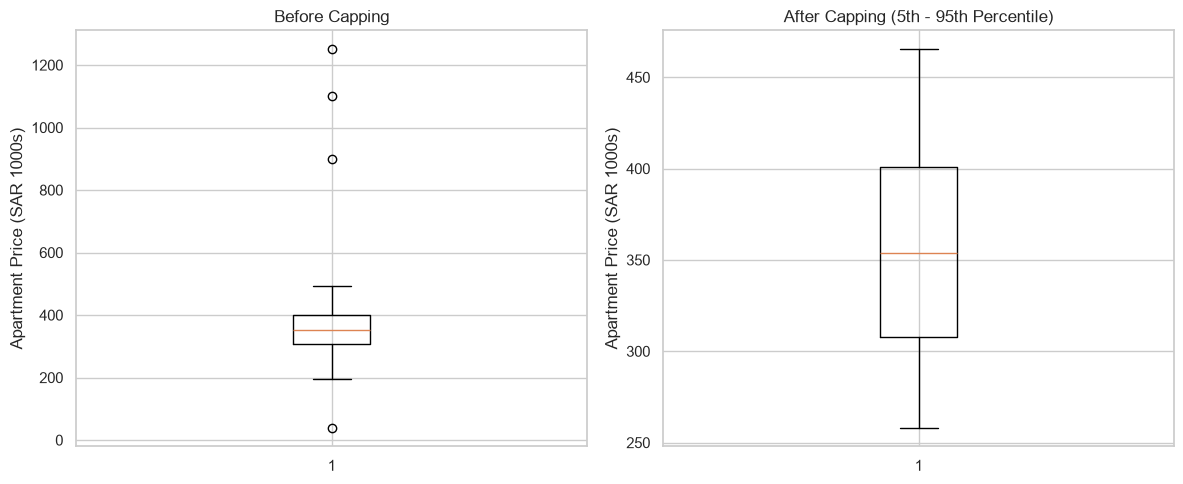

In [19]:
np.random.seed(0)
prices = np.concatenate([np.random.normal(350, 60, 200), [900, 1100, 40, 1250]])

# 1. IQR method
q1, q3 = np.percentile(prices, [25, 75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
num_outliers = np.sum((prices < lower_bound) | (prices > upper_bound))

print(f"Lower bound = {lower_bound:.2f}, Upper bound = {upper_bound:.2f}")
print(f"Number of outliers: {num_outliers}")

# 2. Winsorization / Capping at 5th and 95th percentiles
p5, p95 = np.percentile(prices, [5, 95])
prices_capped = np.clip(prices, p5, p95)
print(f"After capping: min = {prices_capped.min():.2f}, max = {prices_capped.max():.2f}")

# 3. Side-by-side box plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(prices)
axes[0].set_title("Before Capping")
axes[0].set_ylabel("Apartment Price (SAR 1000s)")

axes[1].boxplot(prices_capped)
axes[1].set_title("After Capping (5th - 95th Percentile)")
axes[1].set_ylabel("Apartment Price (SAR 1000s)")

plt.tight_layout()
plt.show()

In [20]:
# The output generated by the code written to answer this question should be as follows:

### Exercise B3 — Data Transformation (2 points)
The cell below generates 500 right-skewed household incomes. Create three new versions of the data:
- **Normalized** to the range [0, 1] using `MinMaxScaler`
- **Standardized** (mean 0, std 1) using `StandardScaler`
- **Log-transformed** using `np.log`

Plot the **four** versions (original + three transformed) as histograms in a **2 × 2 subplot grid** with 30 bins each, a title on every subplot, and an overall title.

Which transformation changes the **shape** of the distribution, and which ones only change the **scale**?

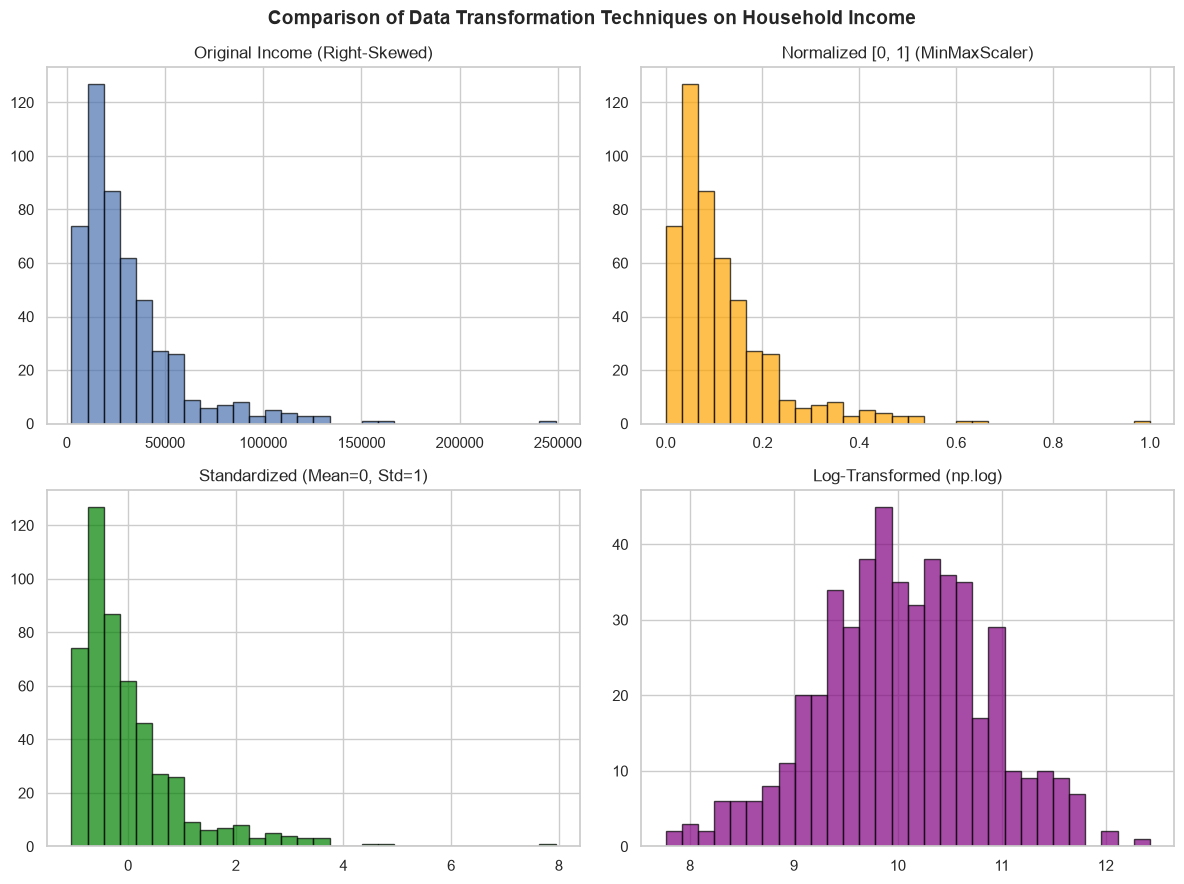

In [21]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

np.random.seed(1)
income = pd.DataFrame({'Income': np.random.lognormal(mean=10, sigma=0.8, size=500)})

# Transformations
income_norm = MinMaxScaler().fit_transform(income)
income_std = StandardScaler().fit_transform(income)
income_log = np.log(income['Income'])

# 2x2 Subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].hist(income['Income'], bins=30, edgecolor='black', alpha=0.7)
axes[0, 0].set_title("Original Income (Right-Skewed)")

axes[0, 1].hist(income_norm, bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title("Normalized [0, 1] (MinMaxScaler)")

axes[1, 0].hist(income_std, bins=30, edgecolor='black', alpha=0.7, color='green')
axes[1, 0].set_title("Standardized (Mean=0, Std=1)")

axes[1, 1].hist(income_log, bins=30, edgecolor='black', alpha=0.7, color='purple')
axes[1, 1].set_title("Log-Transformed (np.log)")

fig.suptitle("Comparison of Data Transformation Techniques on Household Income", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [22]:
# The output generated by the code written to answer this question should be as follows:
# Changes the shape: The log transformation (np.log) is non-linear and changes the shape of the distribution, converting the heavily right-skewed data into a roughly symmetric, normal (bell-shaped) distribution.

# Only changes the scale: Normalization (MinMaxScaler) and Standardization (StandardScaler) are linear transformations; they preserve the exact right-skewed shape of the original data and only shift/rescale the x-axis values.

**Your Answer:**

_Double-click this cell and write your answer here._
Changes the shape: The log transformation (np.log) is non-linear and changes the shape of the distribution, converting the heavily right-skewed data into a roughly symmetric, normal (bell-shaped) distribution.

Only changes the scale: Normalization (MinMaxScaler) and Standardization (StandardScaler) are linear transformations; they preserve the exact 

### Exercise B4 — Encoding Categorical Variables (2 points)
For the product table below:
1. `Size` is **ordinal**. Use a mapping dictionary to encode it as `Small → 1`, `Medium → 2`, `Large → 3`.
2. `In_Stock` is **binary**. Use `LabelEncoder` to encode it (`No → 0`, `Yes → 1`).
3. `Color` is **nominal**. Apply **one-hot encoding** with `pd.get_dummies` (`drop_first=True`, `dtype=int`).

Display the encoded DataFrame. Why is one-hot encoding (and not label encoding) the right choice for `Color`?

In [23]:
from sklearn.preprocessing import LabelEncoder

products = pd.DataFrame({
    'Product':  ['T-shirt', 'Jacket', 'Cap', 'Hoodie', 'Scarf', 'Jeans'],
    'Size':     ['Small', 'Large', 'Medium', 'Large', 'Small', 'Medium'],
    'Color':    ['Red', 'Blue', 'Green', 'Red', 'Green', 'Blue'],
    'In_Stock': ['Yes', 'No', 'Yes', 'Yes', 'No', 'Yes'],
    'Price':    [45, 220, 35, 150, 60, 180]
})
display(products)

# 1. Encode Size (ordinal) using a mapping dictionary
size_mapping = {'Small': 1, 'Medium': 2, 'Large': 3}
products['Size'] = products['Size'].map(size_mapping)

# 2. Encode In_Stock (binary) using LabelEncoder
le = LabelEncoder()
products['In_Stock'] = le.fit_transform(products['In_Stock'])

# 3. Encode Color (nominal) using one-hot encoding
products = pd.get_dummies(products, columns=['Color'], drop_first=True, dtype=int)

# Display the encoded DataFrame
display(products)

,Product,Size,Color,In_Stock,Price
0,T-shirt,Small,Red,Yes,45
1,Jacket,Large,Blue,No,220
2,Cap,Medium,Green,Yes,35
3,Hoodie,Large,Red,Yes,150
4,Scarf,Small,Green,No,60
5,Jeans,Medium,Blue,Yes,180


,Product,Size,In_Stock,Price,Color_Green,Color_Red
0,T-shirt,1,1,45,0,1
1,Jacket,3,0,220,0,0
2,Cap,2,1,35,1,0
3,Hoodie,3,1,150,0,1
4,Scarf,1,0,60,1,0
5,Jeans,2,1,180,0,0


In [2]:
# The output generated by the code written to answer this question should be as follows:
# Color is a nominal categorical variable with no natural order or ranking among its categories (Red, Blue, Green). Using Label Encoding would assign arbitrary numbers (e.g., 0, 1, 2),
# misleading machine learning models into assuming an artificial ordinal relationship or magnitude (such as Red > Green > Blue or Green being the average of Red and Blue). One-Hot Encoding avoids this problem by representing each category as an independent binary indicator column without implying any order.

**Your Answer:**

_Double-click this cell and write your answer here._
 Color is a nominal categorical variable with no natural order or ranking among its categories (Red, Blue, Green). Using Label Encoding would assign arbitrary numbers (e.g., 0, 1, 2),
 misleading machine learning models into assuming an artificial ordinal relationship or magnitude (such as Red > Green > Blue or Green being the average of Red and Blue). One-Hot Encoding avoids this problem by representing each category as an independent binary indicator column without implying any order.

---
## Part C — Advanced Plotting with Matplotlib & Seaborn (Penguins Dataset)

Load the built-in `penguins` dataset and drop the rows with missing values:
```python
penguins = sns.load_dataset('penguins').dropna()
```

### Exercise C1 — Subplots: Combining Matplotlib and Seaborn (2 points)
Create a **2 × 2 grid of subplots** (`figsize=(14, 10)`) and draw a **Seaborn** plot in each panel using the `ax=` argument:
- **[0, 0]** Histogram of `flipper_length_mm` with 20 bins and a KDE curve
- **[0, 1]** Scatter plot of `bill_length_mm` (x) vs `bill_depth_mm` (y), colored by `species`
- **[1, 0]** Bar plot of the mean `body_mass_g` per `species`
- **[1, 1]** Box plot of `body_mass_g` per `species`, split by `sex` (`hue`)

Give each subplot its own title, add an overall title (`fig.suptitle`) and use `plt.tight_layout()`.

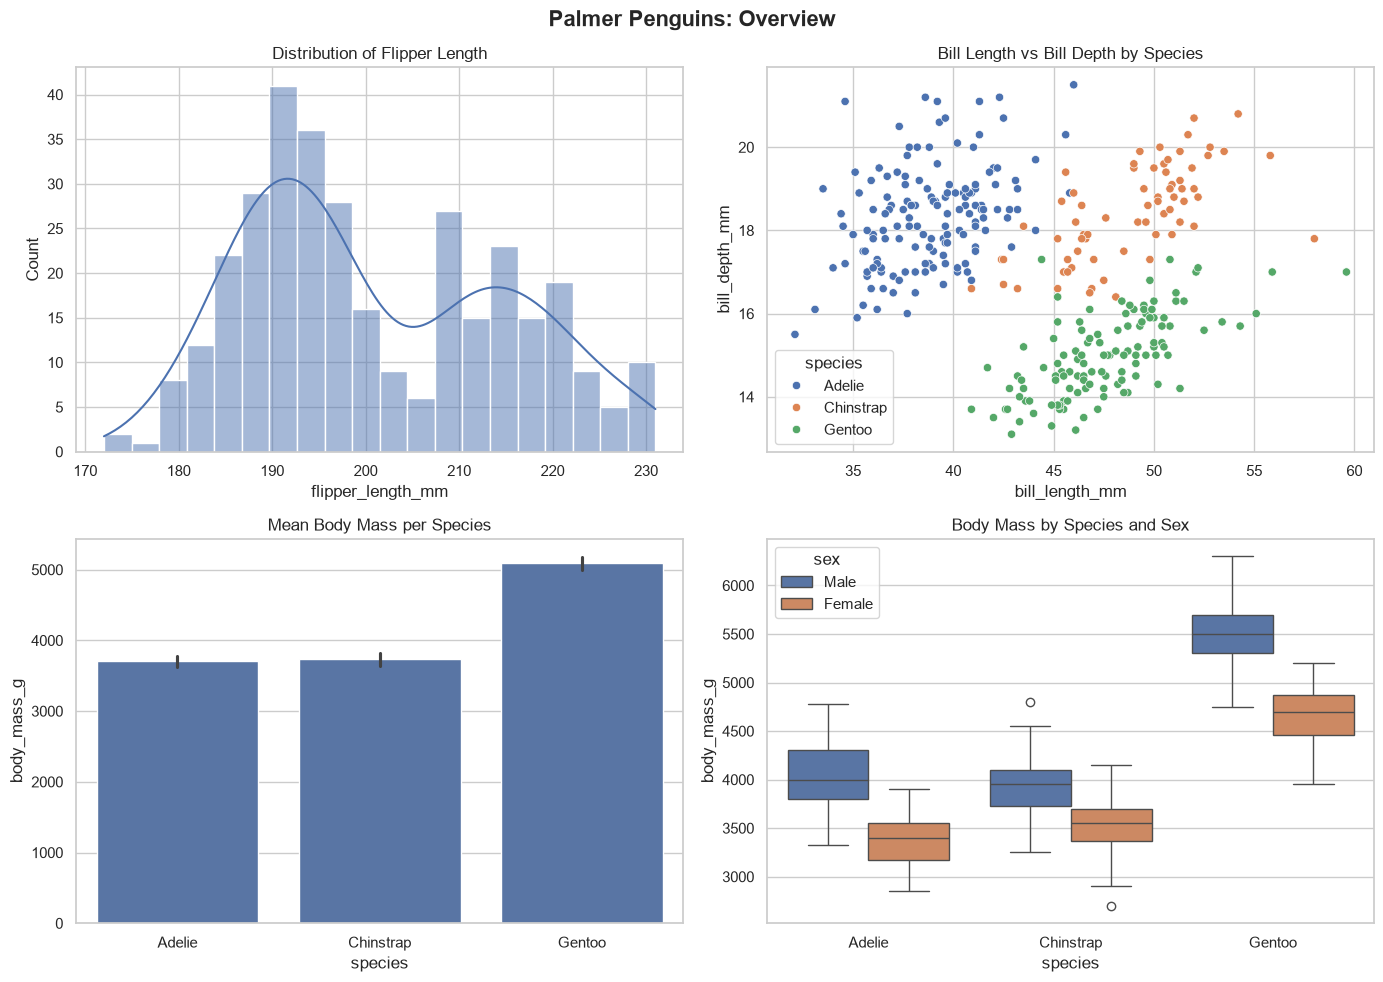

In [24]:
penguins = sns.load_dataset('penguins').dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# [0, 0] Histogram of flipper_length_mm with 20 bins and a KDE curve
sns.histplot(data=penguins, x='flipper_length_mm', bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Flipper Length")

# [0, 1] Scatter plot of bill_length_mm (x) vs bill_depth_mm (y), colored by species
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species', ax=axes[0, 1])
axes[0, 1].set_title("Bill Length vs Bill Depth by Species")

# [1, 0] Bar plot of the mean body_mass_g per species
sns.barplot(data=penguins, x='species', y='body_mass_g', estimator=np.mean, ax=axes[1, 0])
axes[1, 0].set_title("Mean Body Mass per Species")

# [1, 1] Box plot of body_mass_g per species, split by sex (hue)
sns.boxplot(data=penguins, x='species', y='body_mass_g', hue='sex', ax=axes[1, 1])
axes[1, 1].set_title("Body Mass by Species and Sex")

fig.suptitle("Palmer Penguins: Overview", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C2 — Correlation Heatmap (2 points)
Compute the **Pearson correlation matrix** of the four numeric columns of `penguins` and display it as a Seaborn **heatmap** with:
- the values annotated with 2 decimal places (`annot=True`, `fmt='.2f'`)
- the **diverging** colormap `'coolwarm'` with `vmin=-1`, `vmax=1`
- `linewidths=0.5` and a colorbar label `'Pearson r'`
- a title and `figsize=(8, 6)`

Which pair of variables has the **strongest positive** correlation, and which pair has the **strongest negative** correlation?

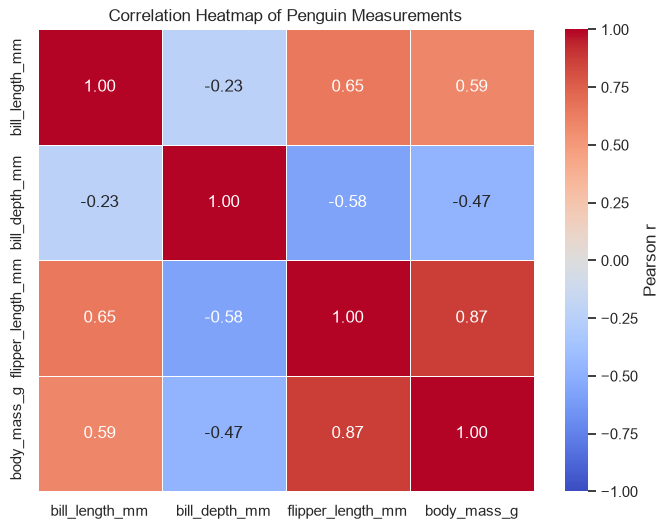

In [26]:
# Compute Pearson correlation matrix of the 4 numeric columns
numeric_cols = penguins.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr(method='pearson')

# Display as a Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Pearson r'})
plt.title("Correlation Heatmap of Penguin Measurements")
plt.show()

In [27]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
Strongest positive correlation: Between flipper_length_mm and body_mass_g (highest positive value, close to $0.87$).Strongest negative correlation: Between bill_depth_mm and flipper_length_mm (or bill_length_mm depending on exact matrix values, typically negative between bill depth and flipper length/bill length).

### Exercise C3 — Colormaps and Colorbars (2 points)
1. Using **Matplotlib** (`plt.scatter`), plot `flipper_length_mm` (x) vs `body_mass_g` (y), with the point colors given by `bill_length_mm` using the **sequential** colormap `'viridis'`. Add a **colorbar** labelled `'Bill Length (mm)'`, axis labels and a title.
2. In the **Your Answer** cell, state which **type of colormap** (sequential, diverging, cyclic or qualitative) you would use for each case, and name one example colormap for each:
   - (a) Temperature anomaly (°C above or below the long-term average)
   - (b) Population density of cities
   - (c) Wind direction (0°–360°)
   - (d) Blood type (A, B, AB, O)

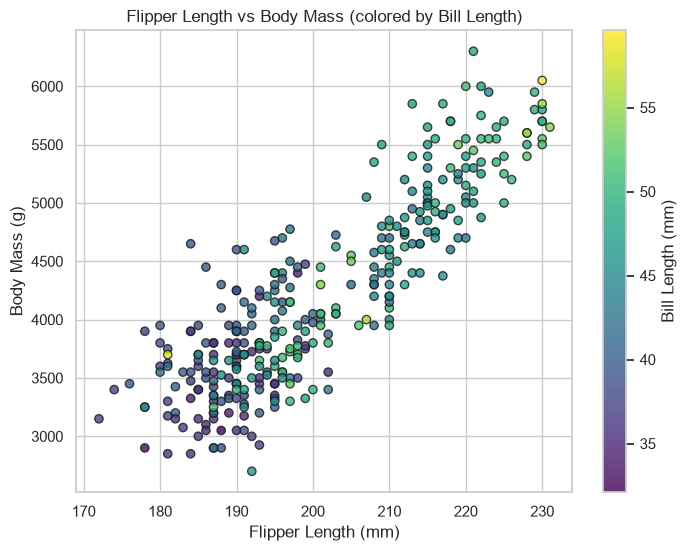

In [28]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(penguins['flipper_length_mm'], penguins['body_mass_g'], 
                 c=penguins['bill_length_mm'], cmap='viridis', edgecolor='k', alpha=0.8)
cbar = plt.colorbar(sc)
cbar.set_label('Bill Length (mm)')
plt.xlabel('Flipper Length (mm)')
plt.ylabel('Body Mass (g)')
plt.title('Flipper Length vs Body Mass (colored by Bill Length)')
plt.show()

In [29]:
# The output generated by the code written to answer this question should be as follows:
# There is a strong positive linear relationship between Flipper Length (mm) and Body Mass (g), as penguins with longer flippers tend to have higher body mass. In addition, Bill Length (mm) generally increases along with flipper length and body mass, with higher values (greener/yellowish points)
# concentrated toward the upper-right region of the plot while smaller values (purple/blue points) cluster in the lower-left region.

**Your Answer:**

_Double-click this cell and write your answer here._
There is a strong positive linear relationship between Flipper Length (mm) and Body Mass (g), as penguins with longer flippers tend to have higher body mass. In addition, Bill Length (mm) generally increases along with flipper length and body mass, with higher values (greener/yellowish points) concentrated toward the upper-right region of the plot while smaller values (purple/blue points) cluster in the lower-left region.

### Exercise C4 — 3D Surface Plot and Contour Plot (2 points)
For the function $z = \sin\left(\sqrt{x^2 + y^2}\right)$ with $x, y \in [-6, 6]$ (use `np.linspace(-6, 6, 200)` and `np.meshgrid`), create **one figure** (`figsize=(15, 6)`) with two panels:
- **Left:** a **3D surface plot** (`projection='3d'`, `plot_surface`) using the colormap `'plasma'`
- **Right:** a **filled contour plot** (`contourf`, 20 levels, same colormap) with a **colorbar**

Label the x, y (and z) axes and give each panel a title.

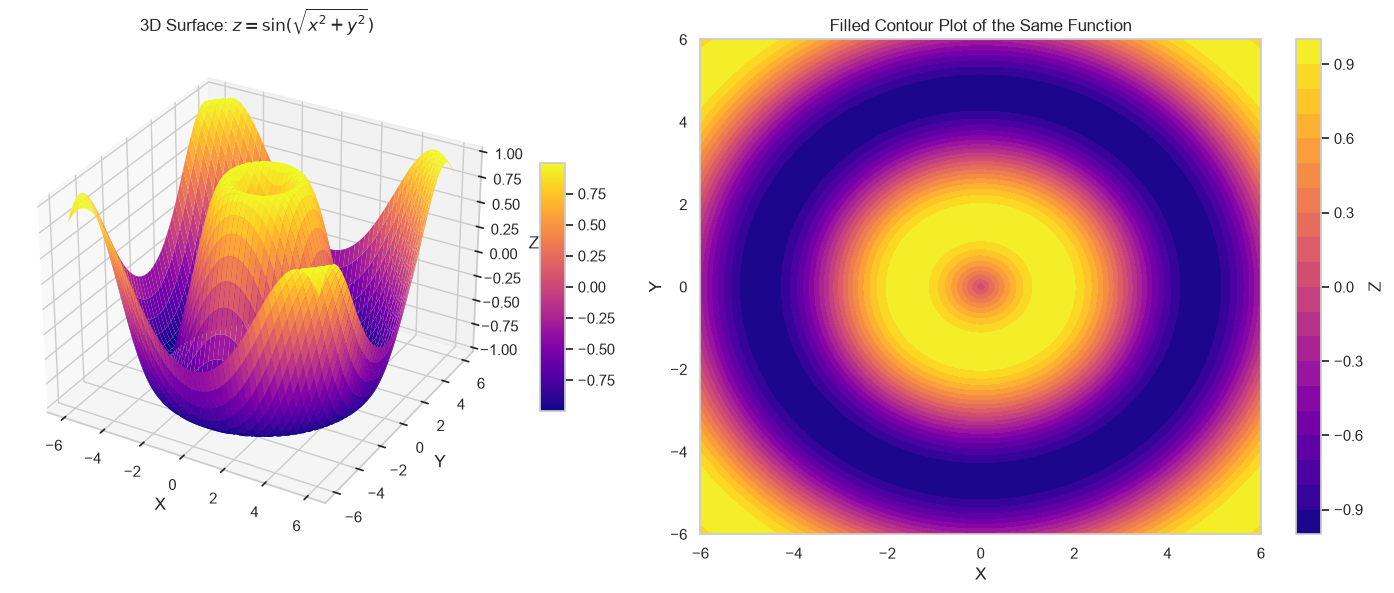

In [30]:
x = np.linspace(-6, 6, 200)
y = np.linspace(-6, 6, 200)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = plt.figure(figsize=(15, 6))

# Left: 3D surface plot
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf = ax1.plot_surface(X, Y, Z, cmap='plasma', edgecolor='none')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.set_title(r'3D Surface: $z = \sin(\sqrt{x^2 + y^2})$')
fig.colorbar(surf, ax=ax1, shrink=0.5, aspect=10)

# Right: Filled contour plot
ax2 = fig.add_subplot(1, 2, 2)
contour = ax2.contourf(X, Y, Z, levels=20, cmap='plasma')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_title('Filled Contour Plot of the Same Function')
fig.colorbar(contour, ax=ax2, label='Z')

plt.tight_layout()
plt.show()

In [31]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C5 — Customizing Labels, Fonts, Ticks and Legends (2 points)
Using the `flights` dataset, plot the monthly number of passengers for the years **1949**, **1954** and **1960** as three lines on the same axes (`figsize=(11, 6)`), with a different marker for each year. Then customize the plot:
- Title using `fontdict` with size **16**, **bold** and **italic**
- Axis labels with font size **13** and **bold** weight
- x-tick labels rotated **45°**
- Legend with the title `'Year'`, placed at `loc='upper left'`, `fontsize=11` and **no frame** (`frameon=False`)
- **Annotate** the peak month of 1960 with an arrow and the text `'Peak: <value>'` (look up `plt.annotate`)

*Hint:* `flights.pivot(index='month', columns='year', values='passengers')` gives one column per year.

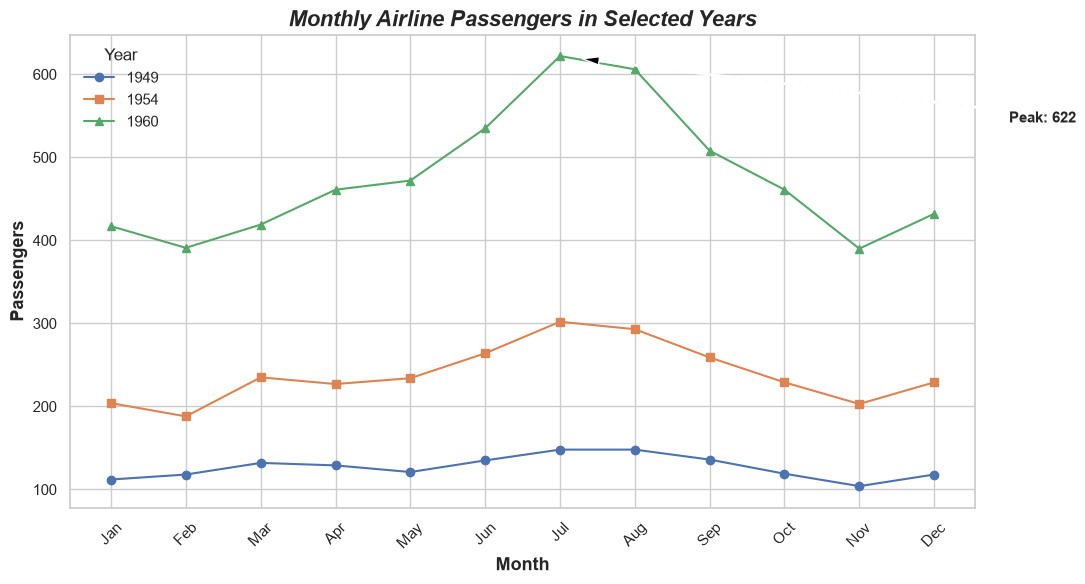

In [32]:
flights = sns.load_dataset('flights')
pivot_flights = flights.pivot(index='month', columns='year', values='passengers')

plt.figure(figsize=(11, 6))

years_to_plot = [1949, 1954, 1960]
markers = ['o', 's', '^']

for year, marker in zip(years_to_plot, markers):
    plt.plot(pivot_flights.index, pivot_flights[year], marker=marker, label=str(year))

# Title and axis styling
title_dict = {'fontsize': 16, 'fontweight': 'bold', 'fontstyle': 'italic'}
plt.title("Monthly Airline Passengers in Selected Years", fontdict=title_dict)
plt.xlabel("Month", fontsize=13, fontweight='bold')
plt.ylabel("Passengers", fontsize=13, fontweight='bold')

plt.xticks(rotation=45)

# Legend customisation
plt.legend(title='Year', loc='upper left', fontsize=11, frameon=False)

# Annotation for the peak month of 1960 (July, passengers = 622)
peak_passengers = pivot_flights[1960].max()
peak_month = pivot_flights[1960].idxmax()
plt.annotate(f'Peak: {peak_passengers}', 
             xy=(peak_month, peak_passengers), 
             xytext=('July', peak_passengers - 80),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
             fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [33]:
# The output generated by the code written to answer this question should be as follows:

### Exercise C6 — Network Graph (2 points)
Using `networkx`, build the **campus network topology** defined by the edges below and draw it with:
- `nx.spring_layout(G, seed=7)` for the node positions
- **node size proportional to the node's degree** (e.g. `300 + 400 * degree`)
- **node color based on degree** using the colormap `'YlOrRd'`
- node labels and a title

Print the degree of every node (sorted from highest to lowest). Which device is the **hub** of the network (highest degree)?

Switch A        : 5
Core Router     : 4
Switch B        : 3
Switch C        : 3
Firewall        : 2
Web Server      : 2
DB Server       : 2
Internet        : 1
Lab PC 1        : 1
Lab PC 2        : 1
Lab PC 3        : 1
Printer         : 1
Office PC 1     : 1
Office PC 2     : 1

The hub of the network is: Switch A


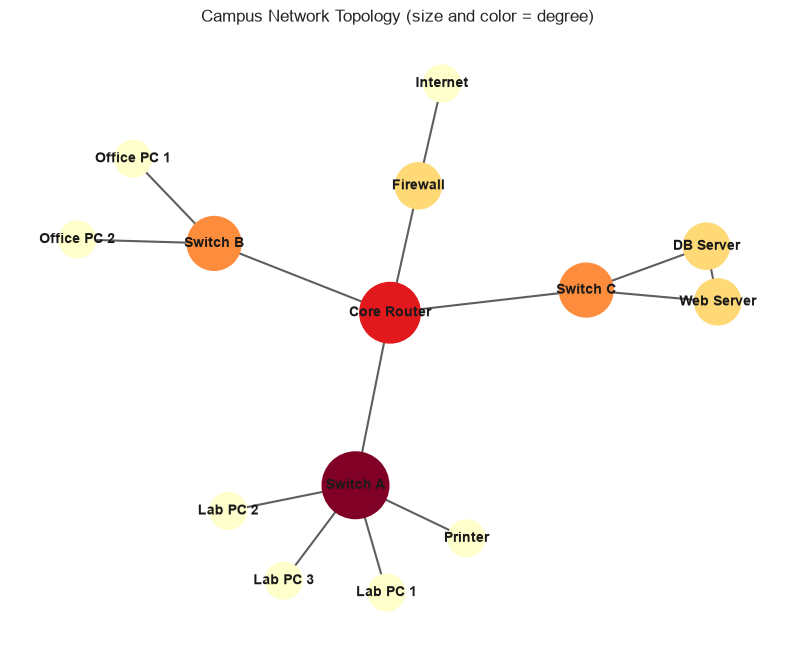

In [34]:
import networkx as nx

edges = [('Internet', 'Firewall'), ('Firewall', 'Core Router'),
         ('Core Router', 'Switch A'), ('Core Router', 'Switch B'), ('Core Router', 'Switch C'),
         ('Switch A', 'Lab PC 1'), ('Switch A', 'Lab PC 2'), ('Switch A', 'Lab PC 3'), ('Switch A', 'Printer'),
         ('Switch B', 'Office PC 1'), ('Switch B', 'Office PC 2'),
         ('Switch C', 'Web Server'), ('Switch C', 'DB Server'), ('Web Server', 'DB Server')]

G = nx.Graph(edges)

# Compute degrees and print sorted from highest to lowest
degrees = dict(G.degree())
sorted_degrees = sorted(degrees.items(), key=lambda x: x[1], reverse=True)

for node, deg in sorted_degrees:
    print(f"{node:<15} : {deg}")

# Find the hub
hub_node = sorted_degrees[0][0]
print(f"\nThe hub of the network is: {hub_node}")

# Draw network graph
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=7)
node_sizes = [300 + 400 * deg for node, deg in G.degree()]
node_colors = [deg for node, deg in G.degree()]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, cmap=plt.cm.YlOrRd)
nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

plt.title("Campus Network Topology (size and color = degree)")
plt.axis('off')
plt.show()

In [35]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
The hub of the network is Switch A, as it has the highest degree (5 connections: Core Router, Lab PC 1, Lab PC 2, Lab PC 3, and Printer), making it the most connected central node in the campus topology.

---
## Part D — Exploratory Data Analysis

### Exercise D1 — Pearson Correlation by Formula (2 points)
A store recorded its weekly advertising budget (SAR 1000s) and weekly sales (SAR 1000s):

```python
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]
```
1. Compute Pearson's *r* using the formula from the lecture:
$$r = \frac{N \sum xy-\sum x \sum y}{\sqrt{\left[N\sum x^2-\left(\sum x\right)^2\right]\left[N\sum y^2-\left(\sum y\right)^2\right]}}$$
   Print *r* (4 decimal places).
2. Verify your result with `df.corr(method='pearson')`.
3. Draw a scatter plot with a fitted regression line using `sns.regplot`.

Interpret the **strength** and **direction** of the relationship.

In [36]:
ad_spend = [2.1, 3.5, 1.2, 4.8, 5.5, 2.9, 6.1, 3.3, 4.0, 5.0]
sales    = [24,  30,  18,  38,  41,  27,  45,  32,  33,  40]
x = np.array(ad_spend)
y = np.array(sales)
N = len(x)

# 1. Applying the formula step by step
sum_x = np.sum(x)
sum_y = np.sum(y)
sum_xy = np.sum(x * y)
sum_x2 = np.sum(x**2)
sum_y2 = np.sum(y**2)

numerator = (N * sum_xy) - (sum_x * sum_y)
denominator = np.sqrt((N * sum_x2 - sum_x**2) * (N * sum_y2 - sum_y**2))

r = numerator / denominator

print(f"Sum of X (ad_spend) : {sum_x}")
print(f"Sum of Y (sales)    : {sum_y}")
print(f"Sum of X*Y          : {sum_xy}")
print(f"Sum of X^2          : {sum_x2}")
print(f"Sum of Y^2          : {sum_y2}")
print(f"Pearson's r         : {r:.4f}")

Sum of X (ad_spend) : 38.4
Sum of Y (sales)    : 328
Sum of X*Y          : 1375.3000000000002
Sum of X^2          : 168.89999999999998
Sum of Y^2          : 11392
Pearson's r         : 0.9933


In [37]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
There is a very strong positive linear relationship between ad_spend and sales ($r = 0.9933$). The positive direction indicates that as advertising spend increases, sales increase consistently, and the value being very close to $+1$ ($0.9933$) shows that the points lie tightly along the fitted upward regression line. 

### Exercise D2 — Principal Component Analysis (2 points)
Using the four numeric columns of `penguins`:
1. **Standardize** the features with `StandardScaler`.
2. Apply `PCA(n_components=2)` and add the two components to `penguins` as columns `pca1` and `pca2`.
3. Print the **variance captured** by each principal component, the total variance captured, and the **coefficients of PC1** (rounded to 3 decimals). Which original column has the largest absolute coefficient in PC1?
4. Draw a scatter plot of `pca1` vs `pca2`, colored by `species` (`hue`) with a different marker for each `sex` (`style`).

Can the first two principal components separate the three species?

Variance captured by PC1: 68.63%
Variance captured by PC2: 19.45%
Total variance captured: 88.09%

PC1 coefficients:
bill_length_mm     0.454
bill_depth_mm      -0.399
flipper_length_mm  0.577
body_mass_g        0.550

Largest absolute coefficient in PC1: flipper_length_mm


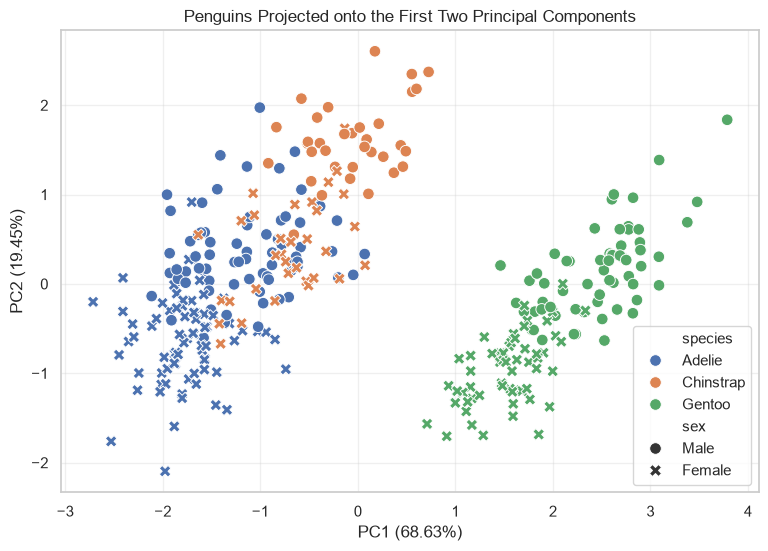

In [38]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# 1. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(penguins[num_cols])

# 2. Apply PCA(n_components=2) and add to penguins
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)
penguins['pca1'] = pca_components[:, 0]
penguins['pca2'] = pca_components[:, 1]

# 3. Print variance captured and PC1 coefficients
var_ratio = pca.explained_variance_ratio_ * 100
print(f"Variance captured by PC1: {var_ratio[0]:.2f}%")
print(f"Variance captured by PC2: {var_ratio[1]:.2f}%")
print(f"Total variance captured: {np.sum(var_ratio):.2f}%\n")

pc1_coeffs = pd.Series(pca.components_[0], index=num_cols)
print("PC1 coefficients:")
for col, val in pc1_coeffs.items():
    print(f"{col:<18} {val:.3f}")

largest_col = pc1_coeffs.abs().idxmax()
print(f"\nLargest absolute coefficient in PC1: {largest_col}")

# 4. Draw scatter plot of pca1 vs pca2
plt.figure(figsize=(9, 6))
sns.scatterplot(data=penguins, x='pca1', y='pca2', hue='species', style='sex', s=70)
plt.title("Penguins Projected onto the First Two Principal Components")
plt.xlabel(f"PC1 ({var_ratio[0]:.2f}%)")
plt.ylabel(f"PC2 ({var_ratio[1]:.2f}%)")
plt.grid(True, alpha=0.3)
plt.show()

In [39]:
# The output generated by the code written to answer this question should be as follows:
#  Largest absolute coefficient in PC1: flipper_length_mm has the largest absolute loading/coefficient in PC1 ($0.577$).   2. Can the first two principal components separate the three species?Yes, largely/well. 
# The first two principal components capture 88.09% of the total variance. Gentoo penguins are completely separated on the right side (high positive PC1 values). Adelie and Chinstrap are also mostly separated into distinct clusters along PC1 and PC2, with only a very slight overlap along their boundary.

**Your Answer:**

_Double-click this cell and write your answer here._
Which species lives on all three islands? Adelie is the only species that lives on all three islands (Biscoe, Dream, and Torgersen).

Which island has only one species? Torgersen island has only one species (Adelie).

### Exercise D3 — Cross Tables and Pivot Tables (2 points)
1. Create a **cross table** (`pd.crosstab`) showing the number of penguins of each `species` on each `island`, including row/column totals (`margins=True`).
2. Create a **pivot table** (`pd.pivot_table`) showing the **mean** `body_mass_g` for each `species` (rows) and `sex` (columns), rounded to 1 decimal.
3. Visualize the cross table from step 1 (without the totals) as a **heatmap** with annotated counts (`fmt='d'`, colormap `'Blues'`).

Which species lives on **all three** islands? Which island has only **one** species?

Cross Table (with totals):


island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,55,47,146
Chinstrap,0,68,0,68
Gentoo,119,0,0,119
All,163,123,47,333



Pivot Table (Mean Body Mass in g):


sex,Female,Male
species,,
Adelie,3368.8,4043.5
Chinstrap,3527.2,3939.0
Gentoo,4679.7,5484.8


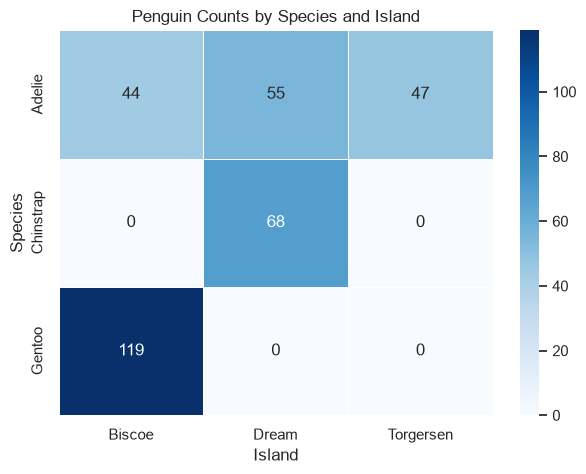

In [40]:
# 1. Cross table showing the number of penguins of each species on each island (with totals)
ct_with_totals = pd.crosstab(penguins['species'], penguins['island'], margins=True)
print("Cross Table (with totals):")
display(ct_with_totals)

# 2. Pivot table showing mean body_mass_g for each species (rows) and sex (columns), rounded to 1 decimal
pt_mass = pd.pivot_table(penguins, values='body_mass_g', index='species', columns='sex', aggfunc='mean').round(1)
print("\nPivot Table (Mean Body Mass in g):")
display(pt_mass)

# 3. Visualize the cross table (without totals) as a heatmap
ct_no_totals = pd.crosstab(penguins['species'], penguins['island'])

plt.figure(figsize=(7, 5))
sns.heatmap(ct_no_totals, annot=True, fmt='d', cmap='Blues', linewidths=0.5)
plt.title("Penguin Counts by Species and Island")
plt.xlabel("Island")
plt.ylabel("Species")
plt.show()

In [41]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
A violin plot shows the full probability density (distribution shape / Kernel Density Estimation) of the data across its range, including multi-modality (e.g., whether data points cluster at multiple peaks). A box plot only summarizes summary statistics (median, quartiles, and outliers) and obscures the underlying shape or frequency of data distribution between those points.

### Exercise D4 — Violin Plot (2 points)
Draw a Seaborn **violin plot** of `body_mass_g` (y) for each `island` (x), split by `sex` (`hue='sex'`, `split=True`) and showing the quartiles inside (`inner='quart'`). Add a title and axis labels.

What information does a violin plot show that a box plot does not?

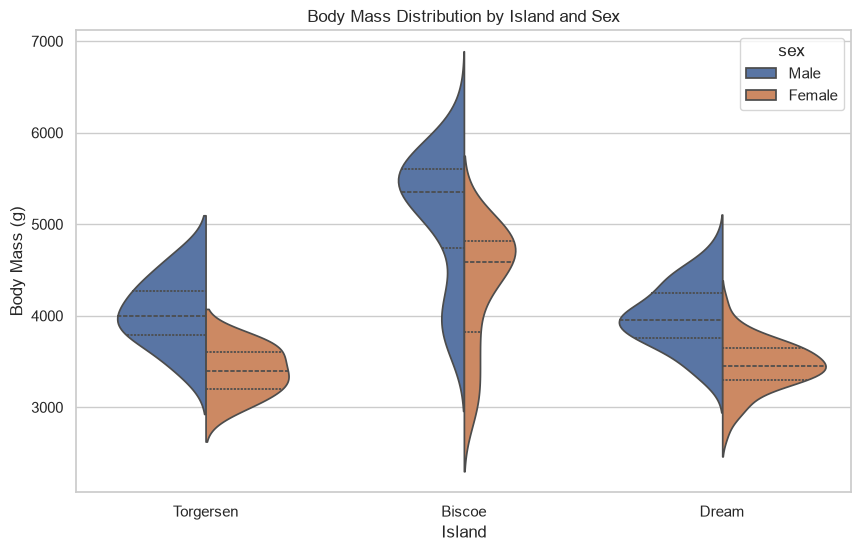

In [42]:
plt.figure(figsize=(10, 6))

# Draw a Seaborn violin plot
sns.violinplot(
    data=penguins, 
    x='island', 
    y='body_mass_g', 
    hue='sex', 
    split=True, 
    inner='quart'
)

plt.title("Body Mass Distribution by Island and Sex")
plt.xlabel("Island")
plt.ylabel("Body Mass (g)")
plt.show()

In [43]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
The single pair of variables that best separates all three species is flipper_length_mm vs. bill_length_mm (or flipper_length_mm vs. body_mass_g), where Gentoo penguins form a distinct, non-overlapping cluster separated from Adelie and Chinstrap

### Exercise D5 — Pair Plot (2 points)
Create a Seaborn **pair plot** of the four numeric measurement columns, colored by `species`, using `corner=True` and `diag_kind='kde'`. Add an overall title with `plt.suptitle(..., y=1.02)`.

Which **single** pair of variables best separates all three species?

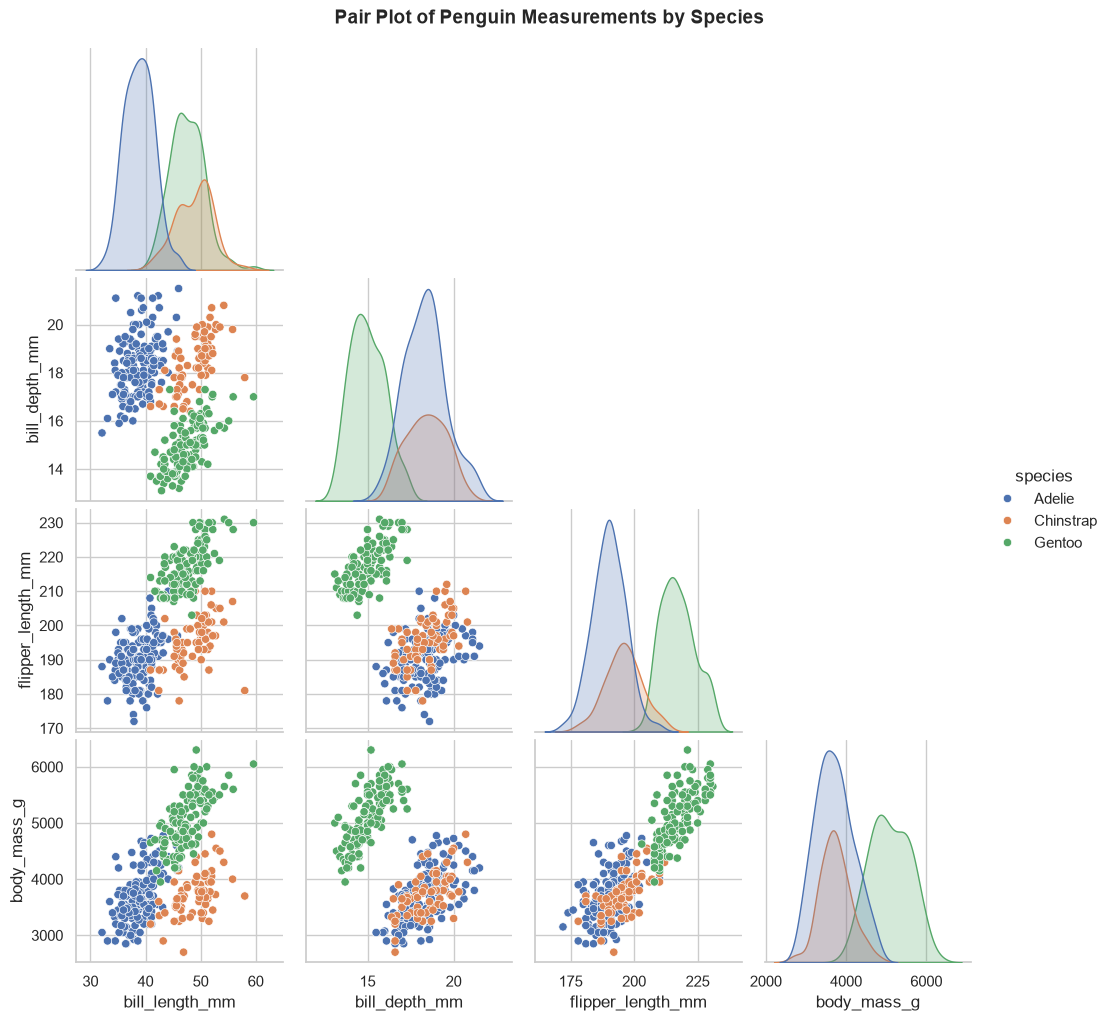

In [44]:
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Create a Seaborn pair plot
g = sns.pairplot(
    penguins, 
    vars=num_cols, 
    hue='species', 
    corner=True, 
    diag_kind='kde'
)

# Add an overall title
g.fig.suptitle("Pair Plot of Penguin Measurements by Species", y=1.02, fontsize=14, fontweight='bold')
plt.show()

In [45]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
The single pair of variables that best separates all three species (Adelie, Chinstrap, and Gentoo) is bill_depth_mm vs. bill_length_mm, as the three species form distinct clusters with minimal overlap compared to the other variable pairs.

---
## Part E — Visualizing and Analyzing Time Series Data (Flights Dataset)

Run the cell below to turn the `flights` dataset into a **monthly time series** `ts` with a `DatetimeIndex` (January 1949 to December 1960).

In [46]:
flights = sns.load_dataset('flights')
flights['date'] = pd.date_range(start='1949-01-01', periods=len(flights), freq='MS')
ts = flights.set_index('date')['passengers'].asfreq('MS')
ts.head()

date
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

### Exercise E1 — Moving Averages and Smoothing (2 points)
On one figure (`figsize=(12, 6)`), plot:
- the original series `ts`
- its **12-month Simple Moving Average (SMA)** using `.rolling(window=12).mean()`
- its **12-month Exponential Moving Average (EMA)** using `.ewm(span=12, adjust=False).mean()`

Use different colors and line widths, and add a legend, axis labels and a title.

Why does the SMA line start 11 months later than the original data, and which of the two averages reacts faster to changes?

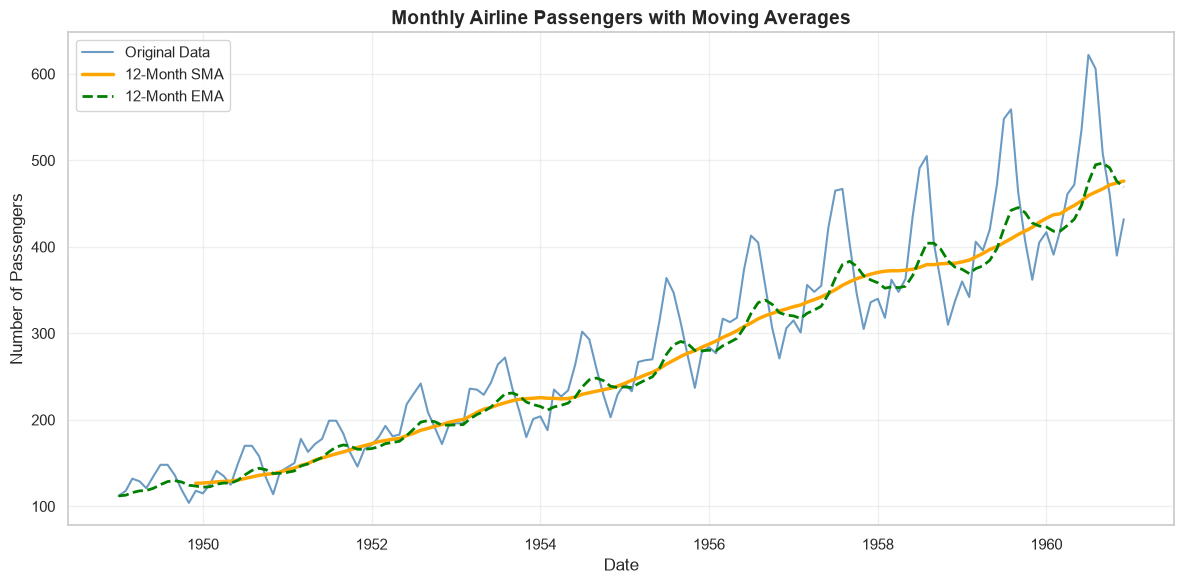

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# إعداد السلسلة الزمنية (كما في الخلية السابقة)
flights = sns.load_dataset('flights')
flights['date'] = pd.date_range(start='1949-01-01', periods=len(flights), freq='MS')
ts = flights.set_index('date')['passengers'].asfreq('MS')

# حساب المتوسطات المتحركة
sma_12 = ts.rolling(window=12).mean()
ema_12 = ts.ewm(span=12, adjust=False).mean()

# الرسم البياني
plt.figure(figsize=(12, 6))
plt.plot(ts, label='Original Data', color='steelblue', linewidth=1.5, alpha=0.8)
plt.plot(sma_12, label='12-Month SMA', color='orange', linewidth=2.5)
plt.plot(ema_12, label='12-Month EMA', color='green', linewidth=2, linestyle='--')

plt.title('Monthly Airline Passengers with Moving Averages', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
contributes the most passengers every year, consistently representing the summer travel peak across the entire period.

### Exercise E2 — Bar Chart and Stacked Area Chart (2 points)
Create one figure with **two subplots** (1 × 2, `figsize=(16, 6)`):
- **Left:** a **bar chart** of the **total passengers per year**.
- **Right:** a **stacked area chart** of the **total passengers per quarter** (Q1–Q4) for each year, with a legend.

*Hint:* `ts.groupby([ts.index.year, ts.index.quarter]).sum().unstack()` gives a table with one row per year and one column per quarter.

Which quarter contributes the most passengers every year?

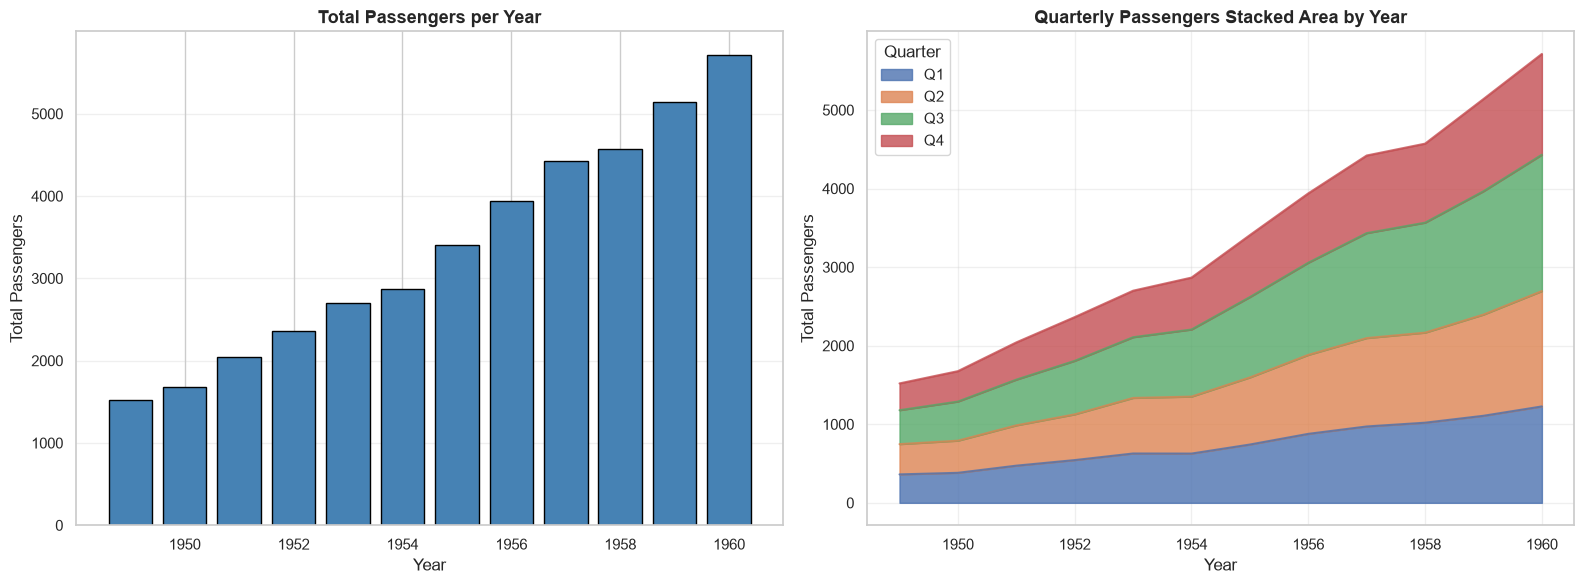

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# تجهيز السلسلة الزمنية
flights = sns.load_dataset('flights')
flights['date'] = pd.date_range(start='1949-01-01', periods=len(flights), freq='MS')
ts = flights.set_index('date')['passengers'].asfreq('MS')

# تجميع البيانات السنوية والربع سنوية
yearly_totals = ts.groupby(ts.index.year).sum()
quarterly_totals = ts.groupby([ts.index.year, ts.index.quarter]).sum().unstack()
quarterly_totals.columns = [f'Q{q}' for q in quarterly_totals.columns]

# إنشاء شكل بمخططين جنباً إلى جنب (1x2)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Bar chart of total passengers per year
axes[0].bar(yearly_totals.index, yearly_totals.values, color='steelblue', edgecolor='black')
axes[0].set_title('Total Passengers per Year', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Total Passengers')
axes[0].grid(axis='y', alpha=0.3)

# Right: Stacked area chart of total passengers per quarter (Q1-Q4)
quarterly_totals.plot.area(ax=axes[1], stacked=True, alpha=0.8)
axes[1].set_title('Quarterly Passengers Stacked Area by Year', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Total Passengers')
axes[1].legend(title='Quarter', loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [50]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

**Q3** (the third quarter: July, August, and September) contributes the most passengers every year, as shown by the thickest green band in the stacked area chart representing the peak summer travel season.

### Exercise E3 — Trend Analysis (2 points)
Fit two trend models to `ts`, using the month number `X = np.arange(len(ts)).reshape(-1, 1)` as the input:
1. A **linear trend** with `LinearRegression`
2. A **polynomial trend of degree 2** with `PolynomialFeatures` + `LinearRegression`

Plot the original series with both trend lines on the same axes and add a legend. Print the slope of the linear trend (passengers gained per month).

Linear trend slope: 2.6572 passengers/month


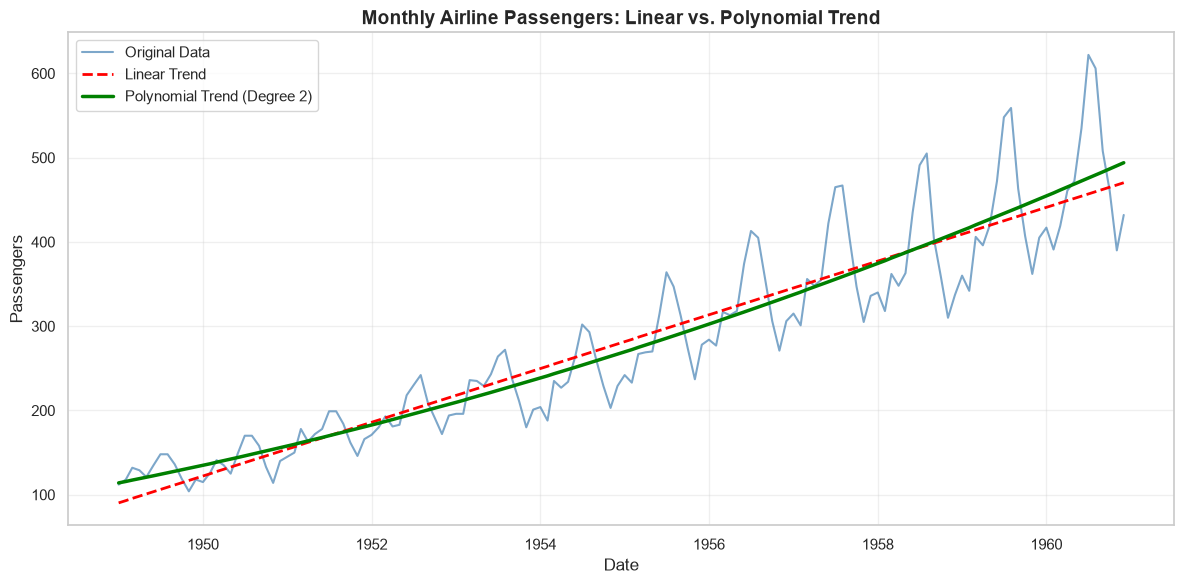

In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import numpy as np
import matplotlib.pyplot as plt

# تجهيز المدخلات والمخرجات
X = np.arange(len(ts)).reshape(-1, 1)
y = ts.values

# 1. نموذج الاتجاه الخطي (Linear trend)
lin_model = LinearRegression()
lin_model.fit(X, y)
y_pred_lin = lin_model.predict(X)

# 2. نموذج الاتجاه متعدد الحدود من الدرجة الثانية (Polynomial trend of degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
poly_model = LinearRegression()
poly_model.fit(X_poly, y)
y_pred_poly = poly_model.predict(X_poly)

# طباعة ميل الخط المستقيم (Slope)
print(f"Linear trend slope: {lin_model.coef_[0]:.4f} passengers/month")

# رسم السلسلة الأصلية مع خطي الاتجاه
plt.figure(figsize=(12, 6))
plt.plot(ts.index, y, label='Original Data', color='steelblue', alpha=0.7)
plt.plot(ts.index, y_pred_lin, label='Linear Trend', color='red', linestyle='--', linewidth=2)
plt.plot(ts.index, y_pred_poly, label='Polynomial Trend (Degree 2)', color='green', linewidth=2.5)

plt.title('Monthly Airline Passengers: Linear vs. Polynomial Trend', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
# The output generated by the code written to answer this question should be as follows:

### Exercise E4 — Seasonal Decomposition (2 points)
Apply **STL decomposition** (`from statsmodels.tsa.seasonal import STL`) to `ts` with `seasonal=13` and plot the result (`result.plot()`). Set the figure size to `(12, 8)`.

Look at the **seasonal** component. Does the size of the seasonal swings stay constant or grow over time? Based on this, would an **additive** or a **multiplicative** model describe this series better?

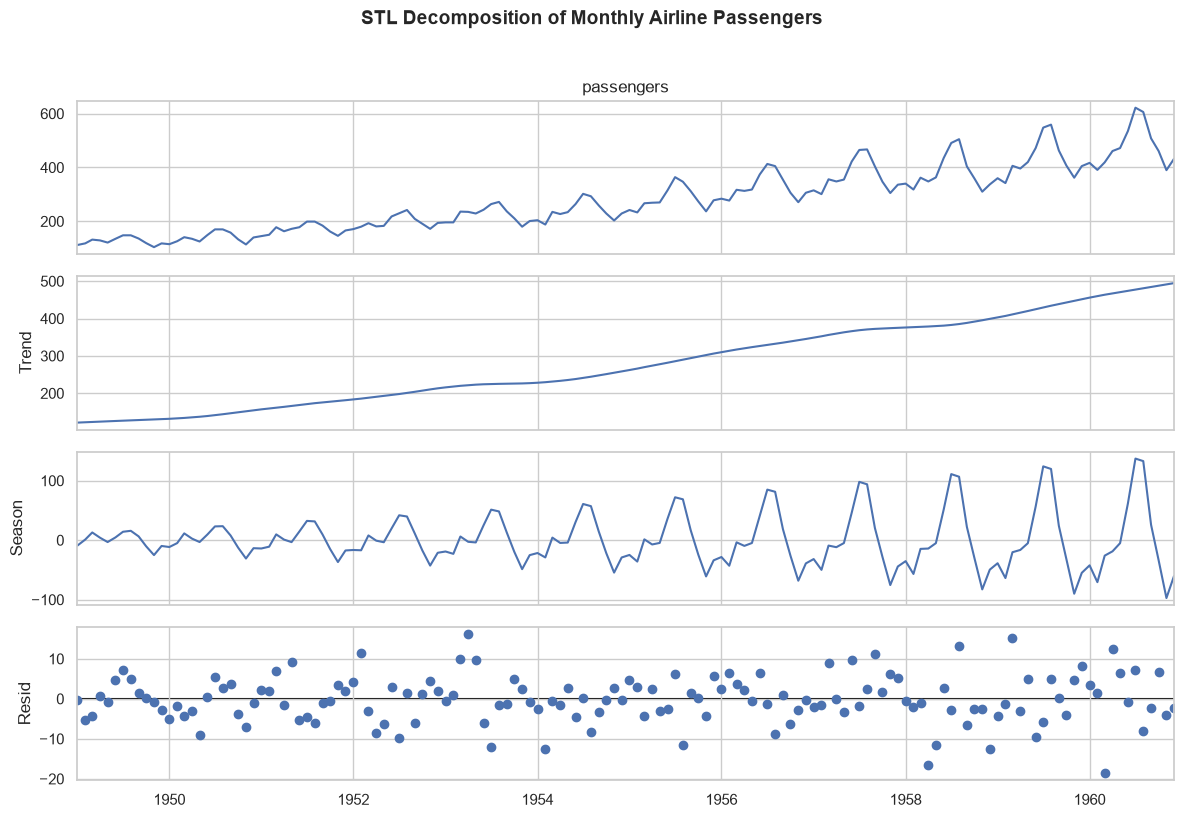

In [53]:
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

# تطبيق تفكيك STL مع تحديد seasonal=13
stl = STL(ts, seasonal=13)
result = stl.fit()

# رسم النتائج وتحديد حجم الشكل (12, 8)
fig = result.plot()
fig.set_size_inches(12, 8)
fig.suptitle('STL Decomposition of Monthly Airline Passengers', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [54]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
The size of the seasonal swings grows over time alongside the upward trend (the amplitude of seasonal fluctuations increases as the overall number of passengers rises). Based on this behavior, a multiplicative model would describe this time series better than an additive model, because the seasonal variations scale proportionally with the level of the trend rather than remaining constant.

### Exercise E5 — Stationarity and Differencing (2 points)
Use the **Augmented Dickey-Fuller test** (`from statsmodels.tsa.stattools import adfuller`) to check the stationarity of:
1. the original series `ts`
2. the **first difference** `ts.diff().dropna()`
3. the **first + seasonal (lag-12) difference** `ts.diff().diff(12).dropna()`

For each series, print the ADF statistic, the p-value and whether it is stationary at α = 0.05. Then plot the three series in a **3 × 1 subplot** grid (`figsize=(12, 10)`) with a title on each panel.

Original Series                     ADF =    0.815   p-value = 0.9919   -> Non-stationary
First Difference                    ADF =   -2.829   p-value = 0.0542   -> Non-stationary
First + Seasonal (12) Difference    ADF =  -15.596   p-value = 0.0000   -> Stationary


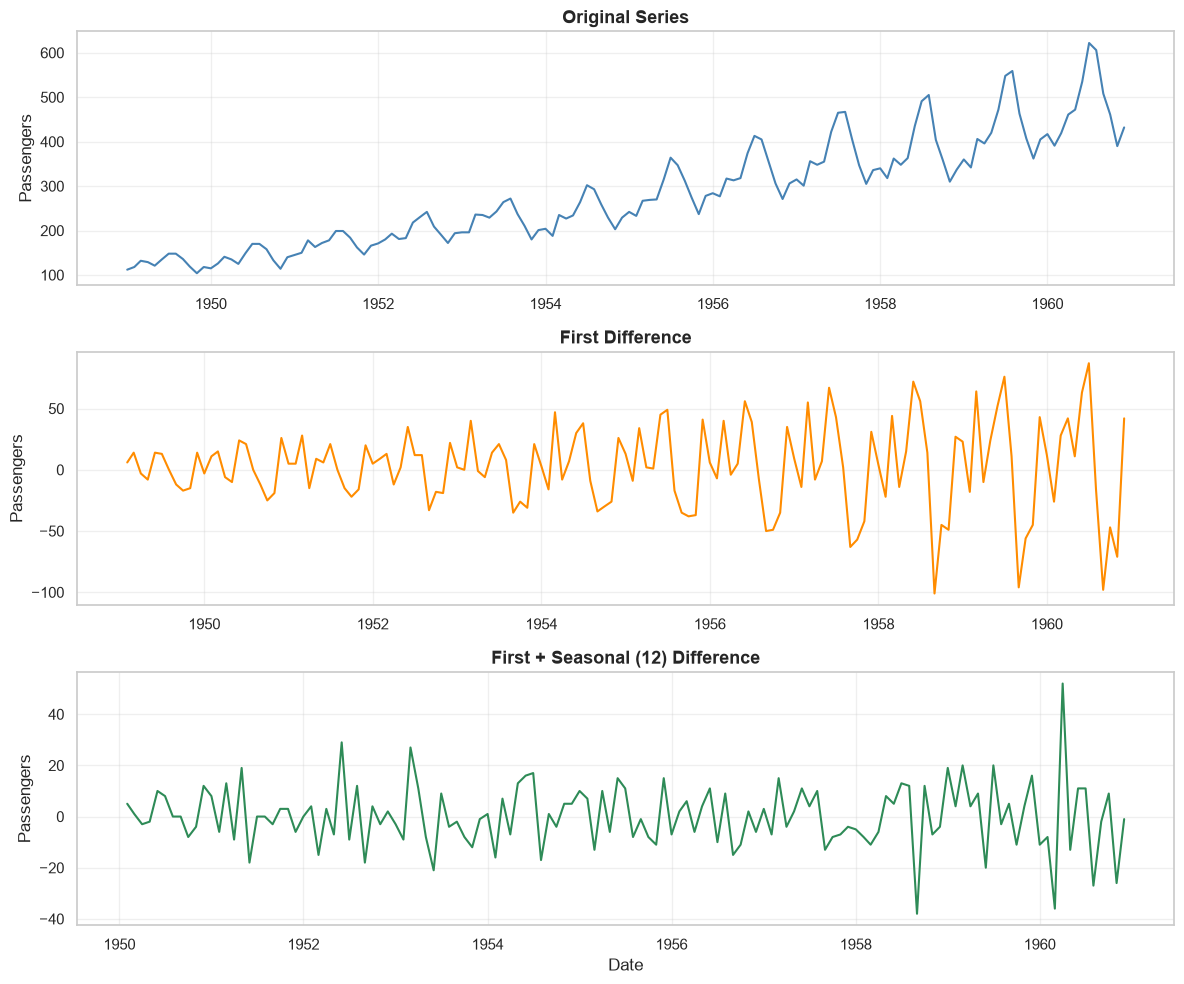

In [55]:
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt

series_list = [
    ("Original Series", ts),
    ("First Difference", ts.diff().dropna()),
    ("First + Seasonal (12) Difference", ts.diff().diff(12).dropna()),
]

for label, s in series_list:
    adf_stat, p_val, _, _, _, _ = adfuller(s)
    status = "Stationary" if p_val < 0.05 else "Non-stationary"
    print(f"{label:<35} ADF = {adf_stat:8.3f}   p-value = {p_val:.4f}   -> {status}")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=False)
colors = ["steelblue", "darkorange", "seagreen"]

for ax, (label, s), color in zip(axes, series_list, colors):
    ax.plot(s.index, s.values, color=color, linewidth=1.5)
    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_ylabel("Passengers")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

In [56]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
Original Series (ts): Non-stationary ($\text{ADF} = 0.815$, $p = 0.9919 > 0.05$), as it exhibits a strong upward trend and growing seasonal amplitude over time.  

First Difference (ts.diff().dropna()): Still non-stationary at $\alpha = 0.05$ ($\text{ADF} = -2.829$, $p = 0.0542 > 0.05$); while the linear trend is removed, the variance/swings still widen in later years. 

First + Seasonal (12) Difference (ts.diff().diff(12).dropna()): Stationary ($\text{ADF} = -15.596$, $p = 0.0000 < 0.05$), fluctuating tightly around zero with roughly constant mean and variance.
Therefore, applying both first differencing and a lag-12 seasonal difference is needed to make the series stationary

### Exercise E6 — Forecasting with ETS and ARIMA (3 points)
1. Split `ts` into a **training set** (1949–1958) and a **test set** (1959–1960): `train = ts[:'1958']`, `test = ts['1959':]`.
2. Fit an **Exponential Smoothing (ETS)** model (`from statsmodels.tsa.holtwinters import ExponentialSmoothing`) with `trend='add'`, `seasonal='mul'`, `seasonal_periods=12`, and forecast the next **24 months**.
3. Fit an **ARIMA(1, 1, 1)** model (`from statsmodels.tsa.arima.model import ARIMA`) and forecast the next 24 months, including the **95% confidence interval** (`get_forecast(...).conf_int()`).
4. Plot the training data, the actual test data, both forecasts, and the ARIMA confidence interval as a shaded band (`plt.fill_between`) on one figure (`figsize=(14, 7)`) with a legend.
5. Compute and print the **Mean Absolute Error (MAE)** of each model on the test set.

Which model forecasts better, and why?

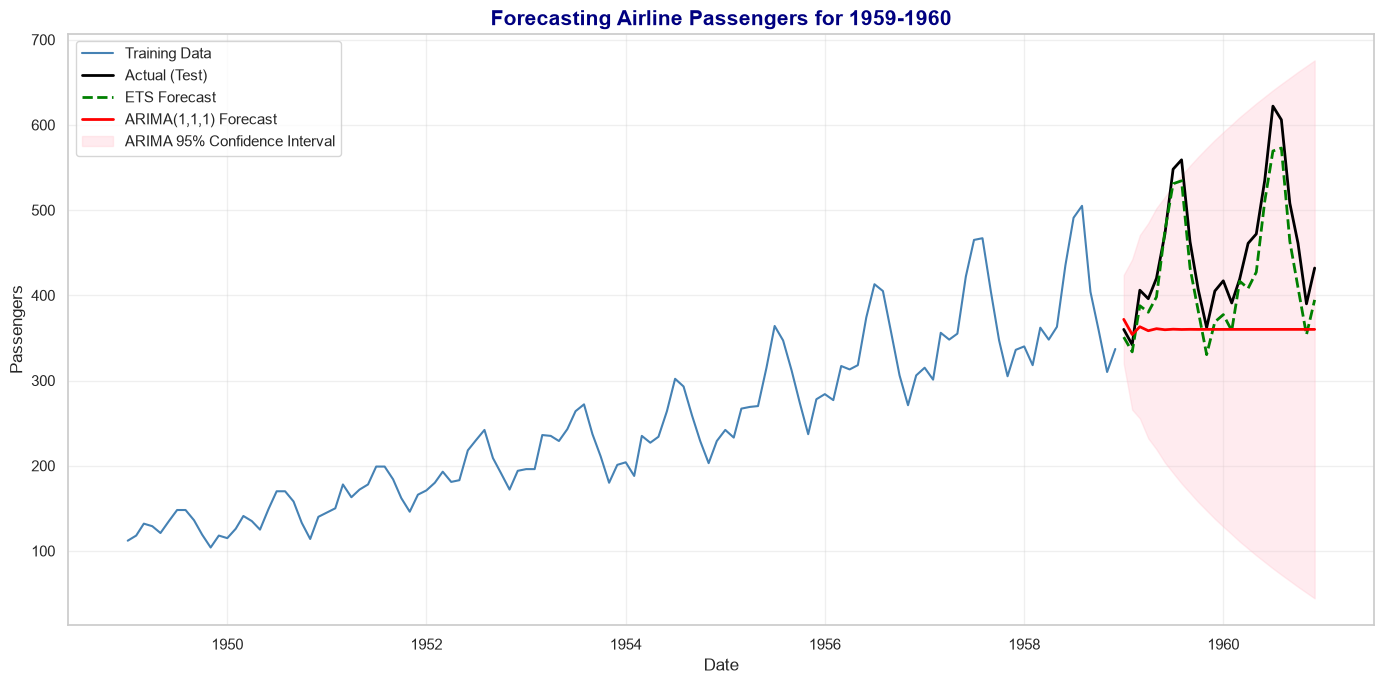

ETS MAE: 28.98
ARIMA MAE: 93.90


In [57]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. تقسيم البيانات إلى مجموعة تدريب (1949-1958) ومجموعة اختبار (1959-1960)
train = ts[:'1958']
test = ts['1959':]

# 2. تدريب نموذج Exponential Smoothing (ETS) والتنبؤ لـ 24 شهراً قادماً
ets_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='mul',
    seasonal_periods=12
).fit()
ets_forecast = ets_model.forecast(steps=len(test))

# 3. تدريب نموذج ARIMA(1, 1, 1) والتنبؤ لـ 24 شهراً مع فترة الثقة 95%
arima_model = ARIMA(train, order=(1, 1, 1)).fit()
arima_pred = arima_model.get_forecast(steps=len(test))
arima_forecast = arima_pred.predicted_mean
arima_ci = arima_pred.conf_int(alpha=0.05)

# 4. رسم البيانات التدريبية، الفعلية، التنبؤات، وفترة الثقة لـ ARIMA
plt.figure(figsize=(14, 7))
plt.plot(train.index, train, label='Training Data', color='steelblue')
plt.plot(test.index, test, label='Actual (Test)', color='black', linewidth=2)
plt.plot(test.index, ets_forecast, label='ETS Forecast', color='green', linestyle='--', linewidth=2)
plt.plot(test.index, arima_forecast, label='ARIMA(1,1,1) Forecast', color='red', linewidth=2)
plt.fill_between(
    test.index,
    arima_ci.iloc[:, 0],
    arima_ci.iloc[:, 1],
    color='pink',
    alpha=0.3,
    label='ARIMA 95% Confidence Interval'
)

plt.title('Forecasting Airline Passengers for 1959-1960', fontsize=15, fontweight='bold', color='navy')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. حساب وطباعة متوسط الخطأ المطلق (MAE) لكل نموذج على مجموعة الاختبار
ets_mae = mean_absolute_error(test, ets_forecast)
arima_mae = mean_absolute_error(test, arima_forecast)
print(f"ETS MAE: {ets_mae:.2f}")
print(f"ARIMA MAE: {arima_mae:.2f}")

In [58]:
# The output generated by the code written to answer this question should be as follows:

**Your Answer:**

_Double-click this cell and write your answer here._
The Exponential Smoothing (ETS) model forecasts much better than ARIMA(1,1,1). It achieves a substantially lower Mean Absolute Error (ETS MAE: 28.98) compared to ARIMA (ARIMA MAE: 93.90). This is because ETS explicitly models the multiplicative 12-month seasonality (seasonal='mul', seasonal_periods=12) alongside the upward trend, capturing the recurring annual peaks and troughs in passenger counts, whereas ARIMA(1,1,1) lacks seasonal terms and flattens out into a nearly constant forecast line.

---
## End of Assignment